<a href="https://colab.research.google.com/github/pachterlab/monod/blob/main/demos/monod_walkthrough.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# *Monod* on Colab

In the current notebook, we apply *Monod* to identify differentially regulated genes between GABAergic and glutamatergic cell types in a single Allen dataset.

# Inference pipeline

## Import Prerequisites

In [ ]:
!pip install -q scanpy

## Install Monod

This installs the pure-Python package. The optional Rust extension (`monod_core`) needs a Rust toolchain and is not built on Colab; everything below runs on the Python code path, just more slowly.

In [ ]:
!git clone -q https://github.com/pachterlab/monod.git
%cd monod
!pip install -q ./
%cd ../

In [ ]:
from monod import extract_data, cme_toolbox, inference, analysis, mminference
from monod.inference import search_result_from_uns, search_result_list_from_uns, searchdata_from_adata
print('monod', __import__('monod').__version__)

## Import data

In [4]:
! git clone https://github.com/pachterlab/monod_examples.git
%cd monod_examples
!git checkout anndata
%cd ../

Cloning into 'monod_examples'...


remote: Enumerating objects: 1983, done.


remote: Counting objects: 100% (144/144), done.
remote: Compressing objects: 100% (97/97), done.


remote: Total 1983 (delta 72), reused 46 (delta 46), pack-reused 1839 (from 1)
Receiving objects: 100% (1983/1983), 1.31 GiB | 7.40 MiB/s, done.


Resolving deltas: 100% (865/865), done.


Updating files: 100% (120/120), done.


/Users/ConradOakes/monod/monod_examples


branch 'anndata' set up to track 'origin/anndata'.
Switched to a new branch 'anndata'


/Users/ConradOakes/monod


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import anndata
from IPython.display import display, Markdown
import scanpy as sc
import anndata as ad
import numpy as np
import os
import zlib
import math
import argparse
from pathlib import Path

In [ ]:
import logging, sys
logging.basicConfig(stream=sys.stdout)
logging.getLogger('monod').setLevel(logging.INFO)   # progress messages from monod only

import warnings
warnings.filterwarnings('ignore')

The printed version above should be 0.3.0 or later; the cells below use that API.

## Import data

In [7]:
def decompress_chunk(compressed_data):
    """Decompress a zlib-compressed bytes object"""
    return zlib.decompress(compressed_data)

def combine_chunks(input_dir, output_file):
    """Combine compressed chunks back into a single h5ad file"""
    # Get all chunk files sorted by name
    chunk_files = sorted(Path(input_dir).glob('chunk_*.gz'))

    # Combine chunks
    combined_data = bytes()
    for chunk_file in chunk_files:
        with open(chunk_file, 'rb') as f:
            compressed_chunk = f.read()
        chunk = decompress_chunk(compressed_chunk)
        combined_data += chunk
        print(f'Processed chunk: {chunk_file}')

    # Write combined data to temporary file
    with open('temp_combined.h5ad', 'wb') as f:
        f.write(combined_data)

    # Load and save as AnnData to ensure proper format
    adata = ad.read_h5ad('temp_combined.h5ad')
    adata.write(output_file)#, compression='gzip')

    # Clean up temporary file
    os.remove('temp_combined.h5ad')
    print(f'Successfully created combined file: {output_file}')

In [8]:
combine_chunks('monod_examples/sample_data/gaba_anndata', 'gaba_example.h5ad')
combine_chunks('monod_examples/sample_data/glu_anndata', 'glu_example.h5ad')

Processed chunk: monod_examples/sample_data/gaba_anndata/chunk_0000.gz
Processed chunk: monod_examples/sample_data/gaba_anndata/chunk_0001.gz


Successfully created combined file: gaba_example.h5ad
Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0000.gz
Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0001.gz


Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0002.gz
Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0003.gz


Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0004.gz
Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0005.gz


Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0006.gz
Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0007.gz


Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0008.gz
Processed chunk: monod_examples/sample_data/glu_anndata/chunk_0009.gz


Successfully created combined file: glu_example.h5ad


### Load data and filter if desired

In [9]:
glu_adata = anndata.read_h5ad('./glu_example.h5ad')

In [10]:
gaba_adata = anndata.read_h5ad('./gaba_example.h5ad')

Create knee plot.

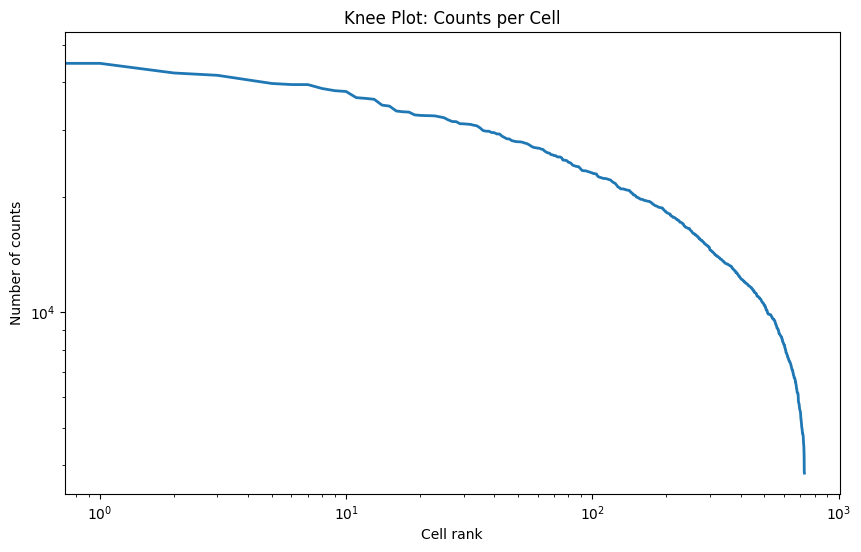

In [11]:
# Calculate number of genes per cell
sc.pp.calculate_qc_metrics(gaba_adata, inplace=True)

# Sort cells by number of genes
total_counts = np.sort(gaba_adata.obs.total_counts)[::-1]

# Create range for x-axis
cell_range = range(len(total_counts))

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(cell_range, total_counts, linewidth=2)

plt.xlabel('Cell rank')
plt.ylabel('Number of counts')
plt.title('Knee Plot: Counts per Cell')

# Add log scales
plt.xscale('log')
plt.yscale('log')

plt.show()

Filter by number of counts if desired.

In [12]:
threshold = 10
sc.pp.filter_cells(gaba_adata, min_counts=threshold)
sc.pp.filter_cells(glu_adata, min_counts=threshold)

## Set up model and perform inference.

Optional Fit Parameters

In [13]:
transcriptome_filepath =  './monod_examples/polyA_ref/gg_200524_mouse_genome_polyA_cum_1'
demo_genes = ['Eif5b','Xrcc5','Klhl12','Rgs7','Thsd7b']
lb, ub, samp_lb, samp_ub, gridsize = None, None, None, None, None # Can add as keywords if desired.

The expected modalities for this model are: ['unspliced', 'spliced']
If your anndata layers have different names, please give a modality dictionary of the form: modality_name_dict  = {'spliced':your_spliced_layer_name, 'unspliced':your_unspliced_layer_name} 
INFO:root:No dataset name given (dataset_string=None). Saving as Bursty_Poisson


INFO:root:Directory Bursty_Poisson created.


INFO:root:Beginning data extraction.


INFO:root:Dataset: Bursty_Poisson


INFO:root:Using default gene filtering parameters


...

INFO:root:Uncertainties per gene calculated, saved to anndata in .var attribute of the form: "error_$\gamma$". Note that the errors are given for log-base 10 parameters.


INFO:root:Grid scan results stored to Bursty_Poisson/Bursty_Poisson_6x7/grid_scan_results.res.


INFO:root:Search Result stored to Bursty_Poisson/Bursty_Poisson_6x7/grid_scan_results.res


INFO:root:Search data stored to Bursty_Poisson/Bursty_Poisson_6x7/search_data.res.


INFO:root:Anndata object stored to Bursty_Poisson/Bursty_Poisson_6x7/monod_adata.pkl


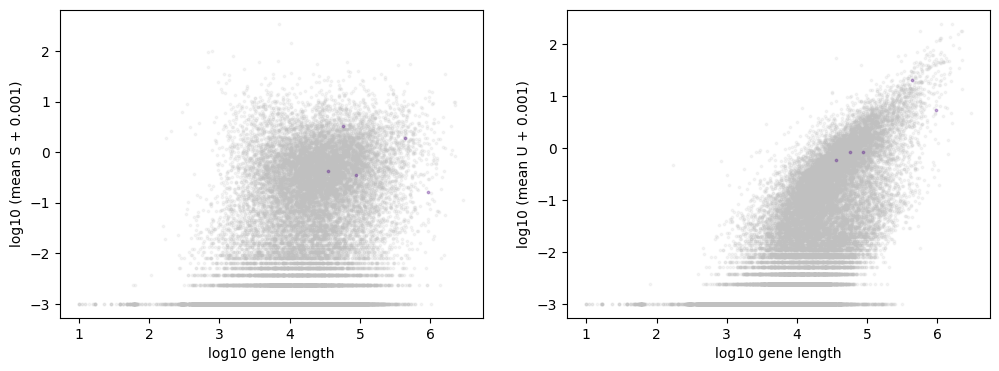

In [14]:
# Define model.
fitmodel = cme_toolbox.CMEModel('Bursty','Poisson')

# Define number of clusters and epochs if using meK-Means, otherwise set to None.
mek_means_params = None # (4,2)

gaba_adata = inference.perform_inference(gaba_adata, fitmodel, genes_to_fit=demo_genes,
                                         transcriptome_filepath=transcriptome_filepath,
                                         num_cores=16, mek_means_params=mek_means_params, n_genes=2,
                                         exclude_sigma = False)

INFO:root:Directory glu_example created.


INFO:root:Beginning data extraction.


INFO:root:Dataset: glu_example


INFO:root:Using default gene filtering parameters


INFO:root:Duplicate variable names found. Making them unique...


...

INFO:root:Uncertainties per gene calculated, saved to anndata in .var attribute of the form: "error_$\gamma$". Note that the errors are given for log-base 10 parameters.


INFO:root:Grid scan results stored to glu_example/Bursty_Poisson_6x7/grid_scan_results.res.


INFO:root:Search Result stored to glu_example/Bursty_Poisson_6x7/grid_scan_results.res


INFO:root:Search data stored to glu_example/Bursty_Poisson_6x7/search_data.res.


INFO:root:Anndata object stored to glu_example/Bursty_Poisson_6x7/monod_adata.pkl


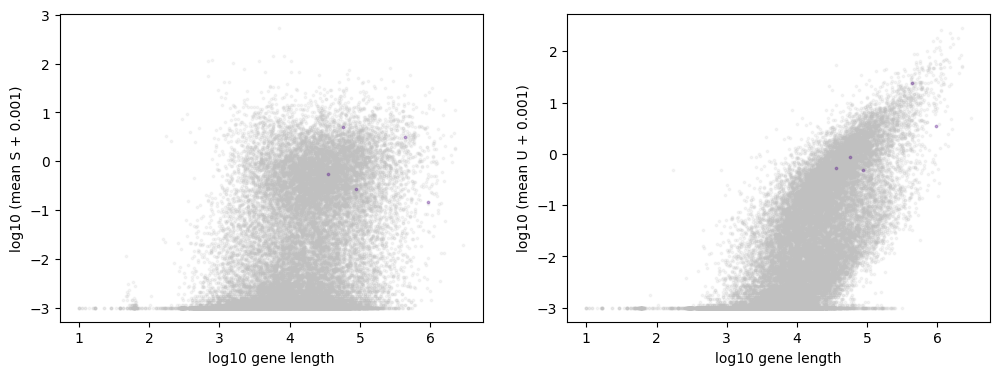

In [15]:
# Fix the genes to be the same as for the gaba data.
genes_to_fit = [i for i in gaba_adata.var_names]
n_genes = len(genes_to_fit)

glu_adata = inference.perform_inference('./glu_example.h5ad', fitmodel, n_genes=n_genes, genes_to_fit=genes_to_fit,
                transcriptome_filepath=transcriptome_filepath, mek_means_params=mek_means_params, num_cores=16,
                                         exclude_sigma = False)

## Access gene info.

In [16]:
# AIC.
display(gaba_adata.var[['AIC']])

# Optimum biological parameters and associated errors.
display(gaba_adata.var[[i for i in gaba_adata.var.keys() if '$' in i]])

,AIC
gene_name,
Eif5b,5079.554315
Xrcc5,2911.339434
Klhl12,2846.619219
Rgs7,8387.555998
Thsd7b,4408.201034


,$b$,$\beta$,$\gamma$,error_$b$,error_$\beta$,error_$\gamma$
gene_name,,,,,,
Eif5b,1.766454,-0.175686,-0.248867,0.042352,0.041512,0.041999
Xrcc5,2.082072,0.290550,1.030607,0.050147,0.041281,0.052989
Klhl12,2.052352,0.030792,0.915332,0.057468,0.051751,0.060354
Rgs7,2.480994,0.014937,0.712543,0.029204,0.024961,0.029286
Thsd7b,1.880694,0.357837,1.294853,0.033945,0.026126,0.054289


In [17]:
# AIC.
display(glu_adata.var[['AIC']])

# Optimum biological parameters and associated errors.
display(glu_adata.var[[i for i in glu_adata.var.keys() if '$' in i]])

,AIC
gene_name,
Eif5b,50339.043825
Xrcc5,21206.130546
Klhl12,26447.489251
Rgs7,81311.696995
Thsd7b,33827.268230


,$b$,$\beta$,$\gamma$,error_$b$,error_$\beta$,error_$\gamma$
gene_name,,,,,,
Eif5b,1.684012,-0.277193,-0.523444,0.014181,0.014225,0.014115
Xrcc5,1.655983,0.127651,0.732127,0.020995,0.019267,0.022763
Klhl12,1.836976,-0.126966,0.588231,0.021149,0.019685,0.021745
Rgs7,2.230788,-0.315222,0.225164,0.008808,0.008006,0.008951
Thsd7b,1.808920,0.435358,1.147444,0.013479,0.009602,0.017837


## Plot parameter distributions.

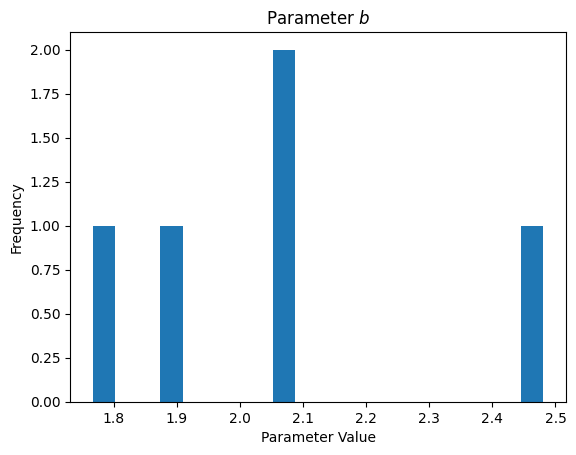

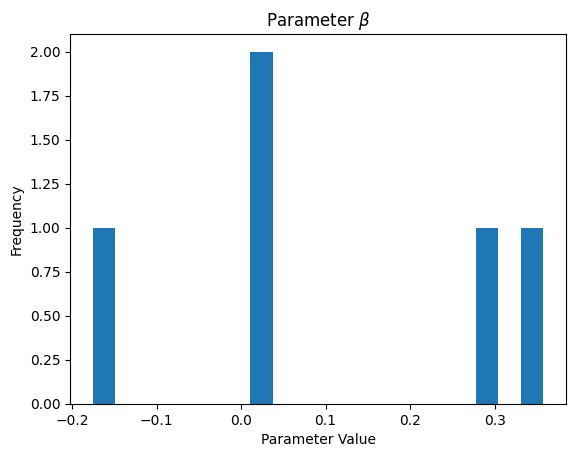

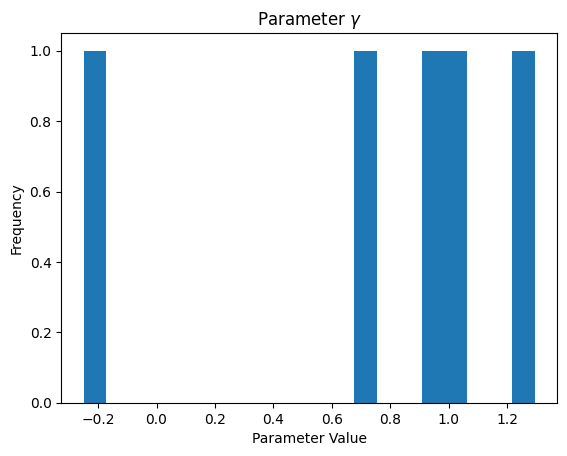

In [18]:
param_names = [i for i in gaba_adata.var.keys() if '$' in i and 'error' not in i]
for name in param_names:
    plt.hist(gaba_adata.var[name], bins=20)
    plt.title('Parameter ' + name)
    plt.xlabel('Parameter Value')
    plt.ylabel('Frequency')
    # plt.savefig(search_result.inference_string + '/parameter_dist_'+ str(i))#'/parameter_dist_{}'.format(
    plt.show()

# Analysis

## Reject genes.

In [ ]:
# Chi-square goodness-of-fit testing; flags poorly fit genes in .var and in the stored results.
gaba_adata = inference.reject_genes(gaba_adata, reject_at_bounds=False, mek_means=mek_means_params)
glu_adata = inference.reject_genes(glu_adata, reject_at_bounds=False, mek_means=mek_means_params)

# Show rejected genes.
display(glu_adata.var[[i for i in glu_adata.var.keys() if 'rejected' in i]])
display(gaba_adata.var[[i for i in gaba_adata.var.keys() if 'rejected' in i]])

# Show chi-squared values and the other rejection statistics.
display(glu_adata.var[[i for i in glu_adata.var.keys() if 'csq' in i or 'pval' in i or 'hellinger' in i]])
display(gaba_adata.var[[i for i in gaba_adata.var.keys() if 'csq' in i or 'pval' in i or 'hellinger' in i]])

In [20]:
#dir(glu_adata.uns['search_result'])

## Execute differential expression analysis.

In [ ]:
# If 2 anndata objects are given, parameters are compared across datasets.
if not mek_means_params:
    DE_genes, DE_filter, offs, residuals = analysis.DE_parameters(glu_adata, gaba_adata,
                                                                  viz=True, use_sigma=True)

# If using meK-Means, compare clusters within one dataset.
else:
    DE_genes_gaba, DE_filter_gaba, offs_gaba, residuals_gaba = analysis.DE_parameters(gaba_adata,
                                                                  viz=True, use_sigma=True, discard_rejected=True,
                                                                  save_cluster_FCs=False)
    clusters = [i for i in DE_genes_gaba.keys()]
    DE_genes = [DE_genes_gaba[i] for i in clusters]
    sr_list = search_result_list_from_uns(gaba_adata.uns['search_result_list'])
    param_names = sr_list[0].model.get_log_name_str()
    param_num, cluster_num = 0, 0
    display(Markdown('E.g. ' + param_names[param_num]))
    print(clusters[cluster_num], DE_genes[cluster_num][param_num])

# Fold-change columns follow the parameter naming ($b$, $\\beta$, $\\gamma$).
display(gaba_adata.var[[i for i in gaba_adata.var.keys() if 'FC' in i]])

### Show some gene distributions.

Results are stored in `adata.uns` as plain dictionaries (no pickling). `search_result_from_uns` rebuilds the `SearchResults` object and `searchdata_from_adata` rebuilds the per-gene histograms from the layers; the plotting methods then take both.

In [ ]:
fitted_adata = glu_adata
search_result = search_result_from_uns(fitted_adata.uns['search_result'])
search_data = searchdata_from_adata(fitted_adata)

# Joint (unspliced x spliced) distributions with the fitted model, then the spliced marginals.
search_result.plot_gene_distributions(search_data, sz=(1, 3), marg='joint', savefig=False)
search_result.plot_gene_distributions(search_data, sz=(1, 3), marg='spliced', savefig=False)
plt.show()

In [ ]:
# Quick QC summary for a fitted AnnData: KL-divergence histogram and joint gene distributions.
analysis.run_qc(gaba_adata, mek_means_params=mek_means_params)